In [1]:
!pip install pm4py

   ---------------------------------------- 0.0/2.7 MB ? eta -:--:--
   --------------- ------------------------ 1.0/2.7 MB 6.4 MB/s eta 0:00:01
   --------------- ------------------------ 1.0/2.7 MB 6.4 MB/s eta 0:00:01
   ------------------------------- -------- 2.1/2.7 MB 3.0 MB/s eta 0:00:01
   ------------------------------- -------- 2.1/2.7 MB 3.0 MB/s eta 0:00:01
   ------------------------------- -------- 2.1/2.7 MB 3.0 MB/s eta 0:00:01
   ---------------------------------------- 2.7/2.7 MB 2.1 MB/s  0:00:01
   ---------------------------------------- 0.0/13.6 MB ? eta -:--:--
   --- ------------------------------------ 1.0/13.6 MB 6.2 MB/s eta 0:00:03
   --- ------------------------------------ 1.0/13.6 MB 6.2 MB/s eta 0:00:03
   --- ------------------------------------ 1.0/13.6 MB 6.2 MB/s eta 0:00:03
   ------ --------------------------------- 2.1/13.6 MB 2.2 MB/s eta 0:00:06
   ------ --------------------------------- 2.1/13.6 MB 2.2 MB/s eta 0:00:06
   ------ -------------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
!pip install plotly

   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.7 MB 4.4 MB/s eta 0:00:03
   ------ --------------------------------- 1.6/9.7 MB 4.2 MB/s eta 0:00:02
   -------- ------------------------------- 2.1/9.7 MB 3.2 MB/s eta 0:00:03
   ----------- ---------------------------- 2.9/9.7 MB 3.1 MB/s eta 0:00:03
   -------------- ------------------------- 3.4/9.7 MB 3.0 MB/s eta 0:00:03
   ---------------- ----------------------- 3.9/9.7 MB 2.9 MB/s eta 0:00:02
   ------------------- -------------------- 4.7/9.7 MB 2.9 MB/s eta 0:00:02
   --------------------- ------------------ 5.2/9.7 MB 2.8 MB/s eta 0:00:02
   ------------------------ --------------- 6.0/9.7 MB 2.9 MB/s eta 0:00:02
   ----------------------------- ---------- 7.1/9.7 MB 2.9 MB/s eta 0:00:01
   -------------------------------- ------- 7.9/9.7 MB 3.0 MB/s eta 0:00:01
   ----------------------------------- ---- 8.7/9.7 MB 3.0 MB/s eta 0:00:01
   ----------------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import shutil
print(shutil.which("dot"))

C:\Program Files\Graphviz\bin\dot.EXE


In [18]:
import pandas as pd
import pm4py
import matplotlib.pyplot as plt
import plotly.graph_objects as go

In [4]:
df = pd.read_csv("../Data/careflow_event_log.csv")

In [5]:
df.head()

,case_id,activity_name,event_timestamp,event_sequence,department,resource,waiting_time_min,duration_min
0,ED-00001,Registration,2026-01-01 00:59:23.000000 UTC,1,Registration,REG-01,0.00,2.80
1,ED-00001,Triage,2026-01-01 01:13:13.000000 UTC,2,Triage,TN-01,11.03,2.53
2,ED-00001,Doctor Consultation,2026-01-01 02:15:47.000000 UTC,3,Emergency Medicine,DR-05,60.03,13.67
3,ED-00001,Lab Test,2026-01-01 02:38:37.000000 UTC,4,Laboratory,LT-03,9.17,6.60
4,ED-00001,Lab Result Received,2026-01-01 03:07:23.000000 UTC,5,Laboratory,LT-02,22.17,1.43


In [6]:
df["event_timestamp"] = pd.to_datetime(
    df["event_timestamp"],
    errors="coerce",
    utc=True
)

In [7]:
df.shape

(10000, 8)

In [8]:
df.isnull().sum()

case_id             0
activity_name       0
event_timestamp     0
event_sequence      0
department          0
resource            0
waiting_time_min    0
duration_min        0
dtype: int64

In [9]:
df.dtypes

case_id                          object
activity_name                    object
event_timestamp     datetime64[ns, UTC]
event_sequence                    int64
department                       object
resource                         object
waiting_time_min                float64
duration_min                    float64
dtype: object

In [10]:
event_log = pm4py.format_dataframe(
    df,
    case_id="case_id",
    activity_key="activity_name",
    timestamp_key="event_timestamp"
)

event_log.head()

,case_id,activity_name,event_timestamp,event_sequence,department,resource,waiting_time_min,duration_min,case:concept:name,concept:name,time:timestamp,@@index,@@case_index
0,ED-00001,Registration,2026-01-01 00:59:23+00:00,1,Registration,REG-01,0.00,2.80,ED-00001,Registration,2026-01-01 00:59:23+00:00,0,0
1,ED-00001,Triage,2026-01-01 01:13:13+00:00,2,Triage,TN-01,11.03,2.53,ED-00001,Triage,2026-01-01 01:13:13+00:00,1,0
2,ED-00001,Doctor Consultation,2026-01-01 02:15:47+00:00,3,Emergency Medicine,DR-05,60.03,13.67,ED-00001,Doctor Consultation,2026-01-01 02:15:47+00:00,2,0
3,ED-00001,Lab Test,2026-01-01 02:38:37+00:00,4,Laboratory,LT-03,9.17,6.60,ED-00001,Lab Test,2026-01-01 02:38:37+00:00,3,0
4,ED-00001,Lab Result Received,2026-01-01 03:07:23+00:00,5,Laboratory,LT-02,22.17,1.43,ED-00001,Lab Result Received,2026-01-01 03:07:23+00:00,4,0


In [11]:
# Sort events in chronological order
event_log = event_log.sort_values(
    by=["case:concept:name", "time:timestamp", "@@index"]
)

# Discover the Directly-Follows Graph
dfg, start_activities, end_activities = pm4py.discover_dfg(
    event_log
)

print("Start Activities:")
print(start_activities)

print("\nEnd Activities:")
print(end_activities)

print("\nProcess Transitions:")
for transition, frequency in sorted(
    dfg.items(),
    key=lambda x: x[1],
    reverse=True
):
    print(f"{transition[0]} → {transition[1]}: {frequency}")

Start Activities:
{'Registration': 1385}

End Activities:
{'Discharge': 1164, 'Admission': 221}

Process Transitions:
Triage → Doctor Consultation: 1508
Registration → Triage: 1385
Treatment → Discharge: 1164
Doctor Consultation → Lab Test: 819
Lab Test → Lab Result Received: 819
Doctor Consultation → Treatment: 698
X-Ray → Treatment: 384
Lab Result Received → X-Ray: 349
Doctor Consultation → X-Ray: 324
Lab Result Received → Treatment: 303
X-Ray → Doctor Consultation: 248
Treatment → Admission: 221
Doctor Consultation → Doctor Consultation: 142
Lab Result Received → Doctor Consultation: 128
Doctor Consultation → Triage: 43
X-Ray → Triage: 41
Lab Result Received → Triage: 39


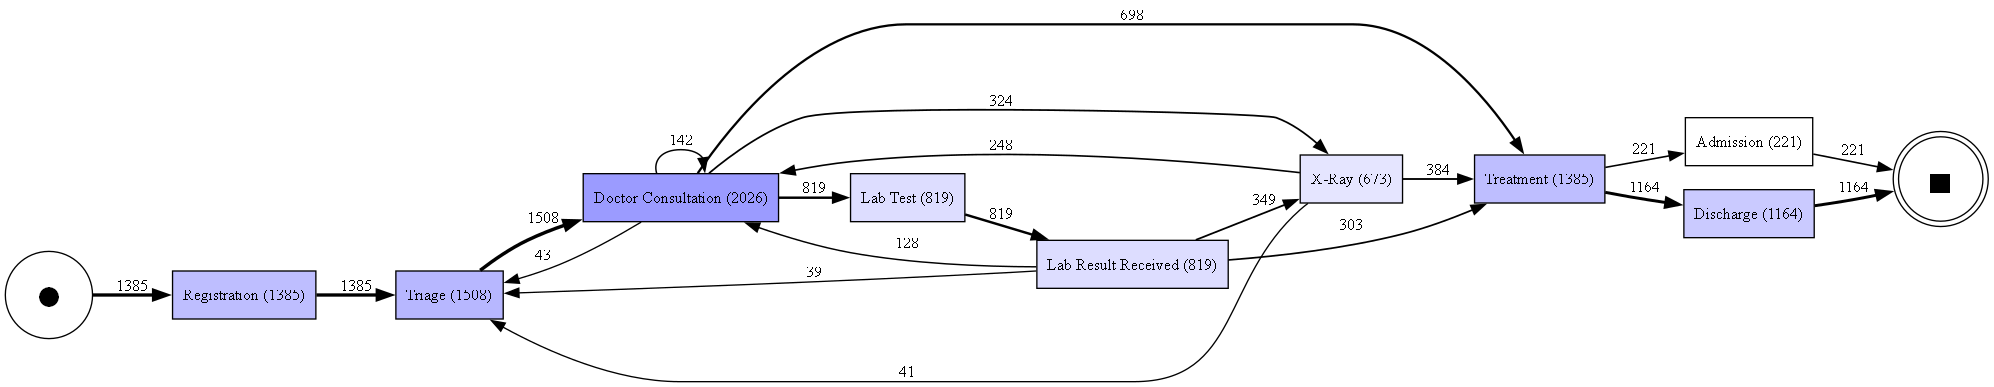

In [12]:
pm4py.view_dfg(
    dfg,
    start_activities,
    end_activities
)

In [13]:
pm4py.save_vis_dfg(
    dfg,
    start_activities,
    end_activities,
    "careflow_process_dfg.png"
)

''

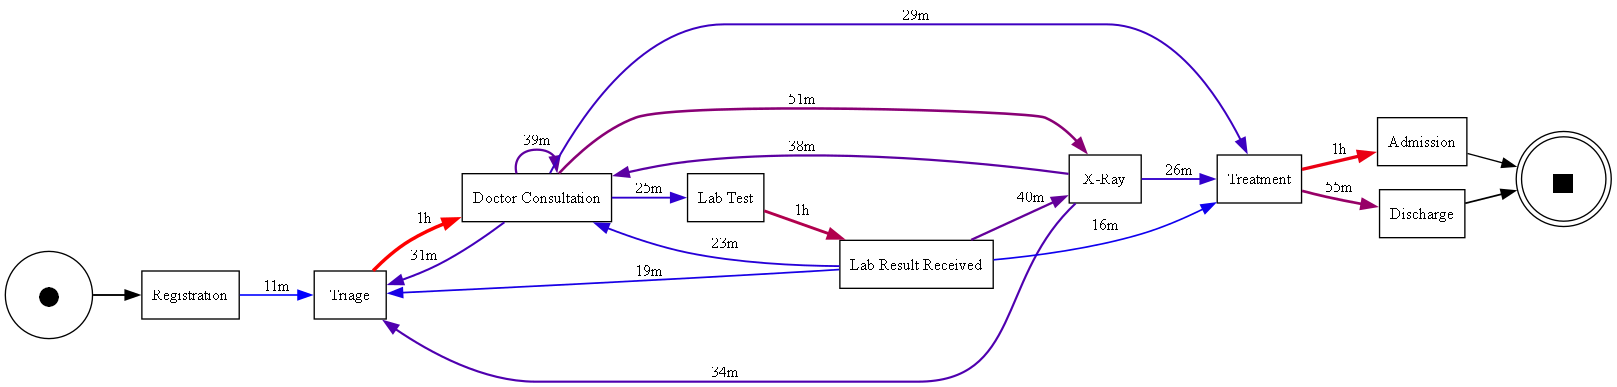

In [14]:
# Discover transition performance
performance_dfg, start_activities, end_activities = (
    pm4py.discover_performance_dfg(event_log)
)

# Display performance graph
pm4py.view_performance_dfg(
    performance_dfg,
    start_activities,
    end_activities
)

In [15]:
# Create a sequence of activities for each patient
patient_routes = (
    event_log
    .sort_values(["case:concept:name", "time:timestamp"])
    .groupby("case:concept:name")["concept:name"]
    .apply(lambda x: " → ".join(x))
)

# Count how frequently each route occurs
route_counts = patient_routes.value_counts()

print("Total unique patient routes:", len(route_counts))

print("\nTop 10 patient routes:")
print(route_counts.head(10))

Total unique patient routes: 51

Top 10 patient routes:
concept:name
Registration → Triage → Doctor Consultation → Treatment → Discharge                                                                                            307
Registration → Triage → Doctor Consultation → Lab Test → Lab Result Received → Treatment → Discharge                                                           170
Registration → Triage → Doctor Consultation → Lab Test → Lab Result Received → X-Ray → Treatment → Discharge                                                   133
Registration → Triage → Doctor Consultation → X-Ray → Treatment → Discharge                                                                                     87
Registration → Triage → Doctor Consultation → Doctor Consultation → Treatment → Discharge                                                                       71
Registration → Triage → Doctor Consultation → Lab Test → Lab Result Received → X-Ray → Treatment → Admission        

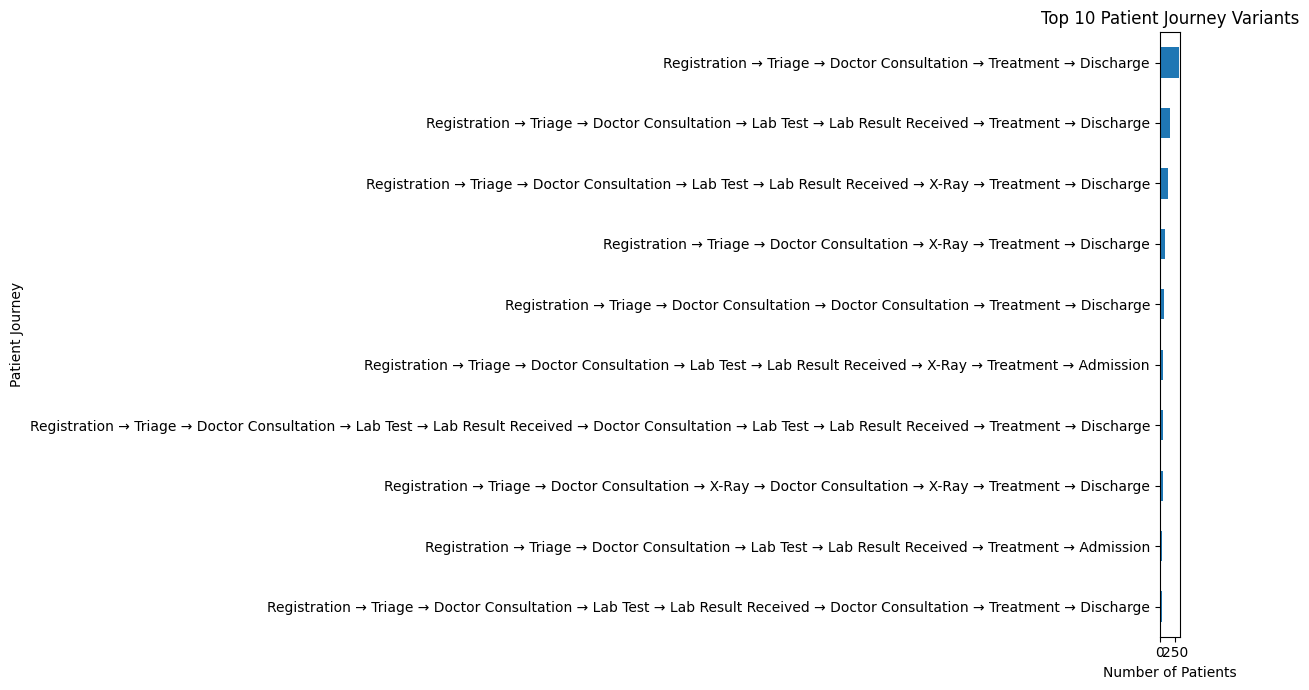

In [16]:
import matplotlib.pyplot as plt

top_routes = route_counts.head(10)

plt.figure(figsize=(12, 7))

top_routes.sort_values().plot(
    kind="barh"
)

plt.title("Top 10 Patient Journey Variants")
plt.xlabel("Number of Patients")
plt.ylabel("Patient Journey")

plt.tight_layout()
plt.show()

In [20]:
# Select 20 patients for visualization
sample_cases = (
    event_log["case:concept:name"]
    .drop_duplicates()
    .head(20)
)

sample_log = event_log[
    event_log["case:concept:name"].isin(sample_cases)
].copy()

sample_log = sample_log.sort_values(
    ["case:concept:name", "time:timestamp"]
)

# Create a separate line for each patient
fig = go.Figure()

for case_id, group in sample_log.groupby("case:concept:name"):

    activities = group["concept:name"].tolist()

    fig.add_trace(
        go.Scatter(
            x=list(range(len(activities))),
            y=[case_id] * len(activities),
            mode="lines+markers",
            name=case_id,
            text=activities,
            hovertemplate=(
                "Patient: %{y}<br>"
                "Activity: %{text}<br>"
                "Sequence: %{x}<extra></extra>"
            )
        )
    )

fig.update_layout(
    title="CareFlow - Patient Journey Spaghetti Diagram",
    xaxis_title="Activity Sequence",
    yaxis_title="Patient Case ID",
    height=750,
    showlegend=False
)

fig.show()

In [21]:
print("Unique Departments:")
print(event_log["department"].unique())

print("\nDepartment Event Counts:")
print(
    event_log["department"]
    .value_counts()
)

Unique Departments:
['Registration' 'Triage' 'Emergency Medicine' 'Laboratory'
 'Discharge Desk' 'Radiology' 'Inpatient Admissions']

Department Event Counts:
department
Emergency Medicine      3411
Laboratory              1638
Triage                  1508
Registration            1385
Discharge Desk          1164
Radiology                673
Inpatient Admissions     221
Name: count, dtype: int64


In [22]:
print("Unique Activities:")
print(event_log["activity_name"].unique())

Unique Activities:
['Registration' 'Triage' 'Doctor Consultation' 'Lab Test'
 'Lab Result Received' 'Treatment' 'Discharge' 'X-Ray' 'Admission']


In [23]:
import plotly.graph_objects as go

# Assign schematic positions to departments
department_positions = {
    "Registration": (0, 2),
    "Triage": (1, 2),
    "Emergency Medicine": (2, 2),
    "Laboratory": (3, 3),
    "Radiology": (3, 1),
    "Discharge Desk": (4, 2),
    "Inpatient Admissions": (4, 3)
}

# Select 30 patients
sample_cases = (
    event_log["case:concept:name"]
    .drop_duplicates()
    .head(30)
)

sample_log = event_log[
    event_log["case:concept:name"].isin(sample_cases)
].copy()

sample_log = sample_log.sort_values(
    ["case:concept:name", "time:timestamp"]
)

fig = go.Figure()

# Draw each patient's department movement
for case_id, group in sample_log.groupby("case:concept:name"):

    x_values = []
    y_values = []
    hover_text = []

    for _, row in group.iterrows():

        department = row["department"]

        if department in department_positions:
            x, y = department_positions[department]

            x_values.append(x)
            y_values.append(y)

            hover_text.append(
                f"Patient: {case_id}<br>"
                f"Activity: {row['activity_name']}<br>"
                f"Department: {department}"
            )

    fig.add_trace(
        go.Scatter(
            x=x_values,
            y=y_values,
            mode="lines+markers",
            name=case_id,
            text=hover_text,
            hovertemplate="%{text}<extra></extra>",
            opacity=0.45
        )
    )

# Draw department locations
for department, (x, y) in department_positions.items():

    fig.add_trace(
        go.Scatter(
            x=[x],
            y=[y],
            mode="markers+text",
            text=[department],
            textposition="top center",
            marker=dict(size=16),
            showlegend=False,
            hoverinfo="text",
            hovertext=department
        )
    )

fig.update_layout(
    title="CareFlow - Schematic Patient Movement Spaghetti Diagram",
    xaxis=dict(visible=False),
    yaxis=dict(visible=False),
    height=700,
    showlegend=False,
    template="plotly_white"
)

fig.show()